In [2]:
import sys
sys.path.append("..")   # lets the notebook import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_paysim

pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

df = load_paysim()
df.shape

(636262, 11)

In [3]:
display(df.head())
display(df.dtypes)
display(df.isna().sum())

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,10,PAYMENT,"19,710.38",C432478797,"21,920.00","2,209.62",M548007256,0.00,0.00,0,0
1,13,CASH_IN,"106,355.58",C827961951,"10,128,904.73","10,235,260.31",C1681374928,"405,210.14","298,854.56",0,0
2,11,CASH_IN,"297,296.04",C1002578318,"172,001.00","469,297.04",C755355682,"1,906,664.63","1,609,400.99",0,0
3,11,CASH_OUT,"255,693.78",C1992302037,"4,860.00",0.00,C1945265288,"30,148.00","285,841.78",0,0
4,18,CASH_OUT,"197,432.45",C1768588531,158.00,0.00,C664243054,985.00,"640,766.40",0,0


step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [4]:
counts = df["isFraud"].value_counts()
print(counts)
print(f"Fraud rate: {df['isFraud'].mean() * 100:.3f}%")

isFraud
0    635386
1       876
Name: count, dtype: int64
Fraud rate: 0.138%


,transactions,frauds,fraud_rate
type,,,
TRANSFER,53570,451,0.01
CASH_OUT,223654,425,0.00
CASH_IN,140079,0,0.00
DEBIT,4098,0,0.00
PAYMENT,214861,0,0.00


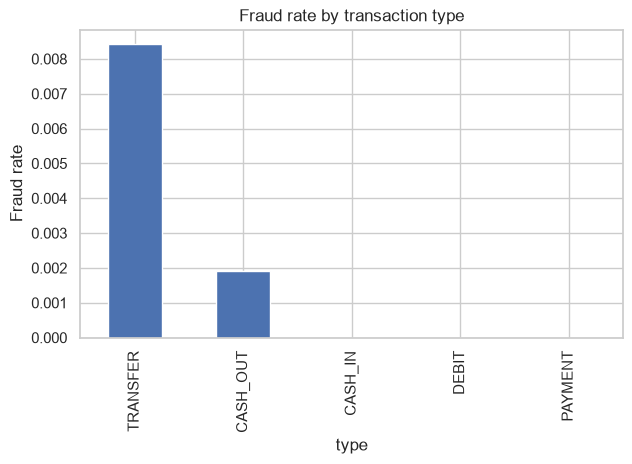

In [5]:
by_type = (
    df.groupby("type")["isFraud"]
      .agg(transactions="count", frauds="sum", fraud_rate="mean")
      .sort_values("fraud_rate", ascending=False)
)
display(by_type)

by_type["fraud_rate"].plot(kind="bar", figsize=(7, 4), title="Fraud rate by transaction type")
plt.ylabel("Fraud rate")
plt.show()

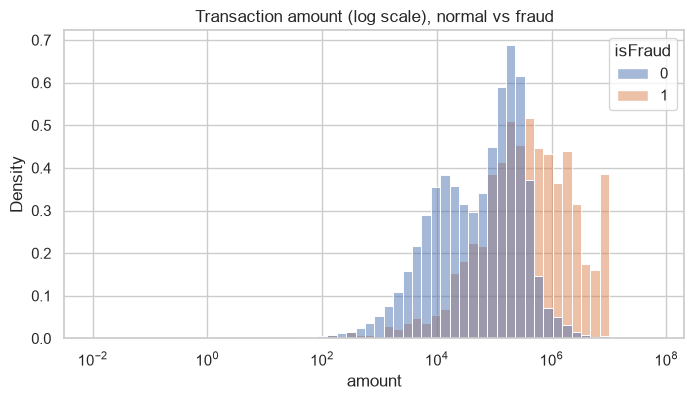

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,"635,386.00","178,256.35","585,011.70",0.01,"13,414.35","74,921.46","208,737.11","66,761,272.21"
1,876.00,"1,382,865.61","2,359,685.53",0.00,"112,832.10","386,759.80","1,424,158.22","10,000,000.00"


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="amount", hue="isFraud", log_scale=True, bins=60,
             stat="density", common_norm=False, ax=ax)
ax.set_title("Transaction amount (log scale), normal vs fraud")
plt.show()

display(df.groupby("isFraud")["amount"].describe())

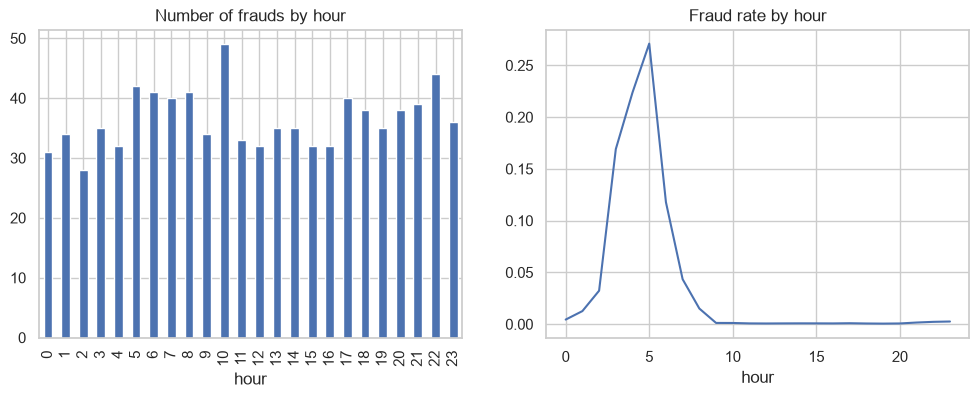

In [7]:
df["hour"] = df["step"] % 24

hourly = df.groupby("hour")["isFraud"].agg(frauds="sum", fraud_rate="mean")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hourly["frauds"].plot(kind="bar", ax=axes[0], title="Number of frauds by hour")
hourly["fraud_rate"].plot(ax=axes[1], title="Fraud rate by hour")
plt.show()

In [8]:
# Does the transaction's balance math add up?
df["errorOrig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
df["errorDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]

display(df.groupby("isFraud")[["errorOrig", "errorDest"]].describe().T)

# Do fraudulent transactions empty the sender's account?
print("Share of transactions that leave the sender at 0 balance:")
print((df["newbalanceOrig"] == 0).groupby(df["isFraud"]).mean())

# The built-in rule-based flag
print("\nisFlaggedFraud vs isFraud:")
display(pd.crosstab(df["isFraud"], df["isFlaggedFraud"]))

# Merchants (names starting with M) vs customers (C)
print("\nDestination type:")
display(pd.crosstab(df["nameDest"].str[0], df["isFraud"]))

isFraud                      0             1
errorOrig count     635,386.00        876.00
          mean      201,467.24      9,005.57
          std       595,929.88    247,444.63
          min            -0.01          0.00
          25%         3,046.11          0.00
          50%        69,479.48          0.00
          75%       251,223.46          0.00
          max    66,761,272.21  7,316,255.05
errorDest count     635,386.00        876.00
          mean       55,227.06    761,442.68
          std       429,117.36  1,888,952.72
          min   -75,549,141.11 -1,645,042.09
          25%             0.00          0.00
          50%         3,492.53     12,786.50
          75%        29,193.26    473,738.02
          max     5,047,595.17 10,000,000.00

Share of transactions that leave the sender at 0 balance:
isFraud
0   0.57
1   0.98
Name: newbalanceOrig, dtype: float64

isFlaggedFraud vs isFraud:


isFlaggedFraud,0,1
isFraud,,
0,635386,0
1,875,1



Destination type:


isFraud,0,1
nameDest,,
C,420525,876
M,214861,0


## Findings

- **Fraud rate:** 0.138% (876 frauds out of 636,262 transactions in my 10% sample). The data is extremely imbalanced, so accuracy would be misleading.
- **Fraud only appears in these transaction types:** TRANSFER (451 frauds, about 0.84% of TRANSFERs) and CASH_OUT (425 frauds, about 0.19% of CASH_OUTs). CASH_IN, DEBIT and PAYMENT have zero fraud.
- **What a typical fraudulent transaction looks like:** Much larger than normal (median about 387,000 vs about 75,000), with amounts topping out at exactly 10,000,000. 98% of frauds leave the sender's account at zero balance (vs 57% of normal transactions), and every fraud goes to a customer account (C), never a merchant (M). Fraud counts are spread evenly across the hours, but normal activity drops overnight, so the fraud rate peaks in the early morning (around hours 2 to 6).
- **Leakage risks I noticed:** newbalanceOrig and newbalanceDest (and the error features I built from them) describe the account after the transaction, so they may not be available when scoring in real time, and they reflect strong simulator patterns. isFlaggedFraud is a weak built-in rule that caught only 1 of 876 frauds. nameOrig and nameDest are ID columns and will be dropped.
- **Two-sentence summary:** Fraud is very rare (0.138%) and only appears in TRANSFER and CASH_OUT transactions, typically with large amounts that drain the sender's account and go to customer accounts. It happens steadily around the clock, so the fraud rate spikes overnight when normal activity is low.